# Motivation and intention

We still use Silverman 2019 (or a trimmed-down version), and consider the effects of augmenting the data to our needs.

See https://medium.com/geekculture/custom-data-augmentation-using-keras-imagedatagenerator-7cfd58e54171

With the trimmed model, we find ...
- all data augmentations, for smooth accuracy curves: training acc. 92.03, val acc. 91.95 percent (class), training acc. 22.78, val acc. 22.66 (rule)
- ...

# Loading packages and functions

In [1]:
# !pip install cellpylib
# import cellpylib as cpl

# TensorFlow and tf.keras
import tensorflow as tf
from tensorflow import keras

print(tf.__version__)

# Helper libraries
import numpy as np
import matplotlib.pyplot as plt
import sklearn as sk
import pandas as pd
import os
import json

# fix random seed for reproducibility
seed = 2023
np.random.seed(seed)

from sklearn.model_selection import train_test_split

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten, BatchNormalization, Activation
from tensorflow.keras.layers import Conv2D, MaxPooling2D, GlobalMaxPooling2D
from tensorflow.keras.constraints import max_norm
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.models import load_model
from tensorflow.keras import Input

2.15.0


In [2]:
# uncomment if you want to use Drive

from google.colab import drive
drive.mount('/content/gdrive')

images_dir = '/content/gdrive/My Drive/Colab Notebooks/Cellular Automata/Spacetime Diagram Classification/Images'
models_dir = '/content/gdrive/My Drive/Colab Notebooks/Cellular Automata/Spacetime Diagram Classification/Models'
files_dir = '/content/gdrive/My Drive/Colab Notebooks/Cellular Automata/Spacetime Diagram Classification/Files'
# !ls '/content/gdrive/My Drive/'

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


In [10]:
# Load function to show accuracy and loss history

def plot_history(history, steps_per_epoch = 0, y_axis_bounds = None, show_val=True, show_loss=True):

    if steps_per_epoch >0:
        xvals = int(steps_per_epoch)*np.array(history.epoch)
        xlab = 'Weight update steps'
    else:
        xvals = np.array(history.epoch)
        xlab = 'Epochs'

    if show_loss:
      plt.figure(figsize = (12,4))
      plt.subplot(1,2,1)
    else:
      plt.figure(figsize= (6,4))
    plt.xlabel(xlab)
    plt.ylabel('Accuracy')
    plt.plot(xvals, np.array(history.history['accuracy']),'g-',
             label='Train accuracy')
    if show_val:
      plt.plot(xvals, np.array(history.history['val_accuracy']),'r-',
             label = 'Validation accuracy')
    if y_axis_bounds:
        plt.ylim(y_axis_bounds)
    plt.legend()

    if show_loss:
      plt.subplot(1,2,2)
      plt.xlabel(xlab)
      plt.ylabel('Loss minimised by model')
      plt.plot(xvals, np.array(history.history['loss']),'g-',
              label='Train loss')
      if show_val:
        plt.plot(xvals, np.array(history.history['val_loss']),'r-',
              label = 'Validation loss')
    plt.legend()

In [11]:
# Load function to translate rule to Li-Packard classes or to equivalent rule (for loading/showing data)
# Note: This function is very poorly designed (slow)

def whichClass(dictionary, rules, class_to_num=None):
    keys = []
    for i, rule in enumerate(rules):
      for key, array in dictionary.items():
          if np.isin(rule, array):
            if class_to_num: # digits rather than strings
              keys.append(class_to_num[key])
            else: # strings rather than digits
              keys.append(key)
    return np.array(keys)

# Loading and showing data

In [12]:
OUTPUT_TYPE = 'classes' # choose between 'rules', 'independent', 'classes'

# Choose validation set fraction
val_frac = 1/4

# give the right names for the files we will import. Training set
train_name_prefix = "ECAs_1024sims-per-rule_64x64"
train_diagram_name = train_name_prefix + "_train_diagrams.npy"
if OUTPUT_TYPE == 'rules':
  train_name_suffix = "_train_labels.npy"
elif OUTPUT_TYPE == 'independent':
  train_name_suffix = "_train_labels_indep.npy"
elif OUTPUT_TYPE == 'classes':
  train_name_suffix = "_train_labels_class.npy"
train_label_name = train_name_prefix + train_name_suffix

# give the right names for the files we will import. Test set
test_name_prefix = "ECAs_128sims-per-rule_64x64"
test_diagram_name = test_name_prefix + "_test_diagrams.npy"
if OUTPUT_TYPE == 'rules':
  test_name_suffix = "_test_labels.npy"
elif OUTPUT_TYPE == 'independent':
  test_name_suffix = "_test_labels_indep.npy"
elif OUTPUT_TYPE == 'classes':
  test_name_suffix = "_test_labels_class.npy"
test_label_name = test_name_prefix + test_name_suffix

# Load the data. Training set
x_train_all = np.load(f"{files_dir}/{train_diagram_name}")
r_train_all = np.load(f"{files_dir}/{train_label_name}")

# Load the data. Test set
x_test = np.load(f"{files_dir}/{test_diagram_name}")
r_test = np.load(f"{files_dir}/{test_label_name}")

# take examples from the data set to show below
rules_example = np.array([168, 232, 178, 154, 161]) # final rules in table of Li-Packard
indices_example = int(x_train_all.shape[0]/256)*rules_example
x_train_example = np.take(x_train_all, indices_example, axis=0)
r_train_example = np.take(r_train_all, indices_example, axis=0)

# Shuffle test data at random, keeping the relation between diagrams and labels
shuffle_indices = np.random.permutation(range(r_train_all.shape[0]))
x_train_all = x_train_all[shuffle_indices]
r_train_all = r_train_all[shuffle_indices]

# Split training data in a training and validation set
val_size = int(x_train_all.shape[0]*val_frac)
x_train, x_val, r_train, r_val = train_test_split(x_train_all, r_train_all, test_size=val_size, random_state=0, shuffle=True, stratify=r_train_all)

# Translate rule to Li-Packard class
with open(f"{files_dir}/all_Li-Packard_dict.json", "r") as fp:
    # Load the dictionary from the file
    Li_Packard_dict = json.load(fp)

with open(f"{files_dir}/equiv_ECA_rules.json", "r") as fp:
    # Load the dictionary from the file
    equiv_ECA_rules = json.load(fp)

# Change key names to digits
class_to_num = dict({'null':0, 'fixed point':1, 'periodic':2, 'locally chaotic':3, 'chaotic':4})
num_to_class = dict({0:'null', 1:'fixed point', 2:'periodic', 3:'locally chaotic', 4:'chaotic'})

# Change key names to digits
indep_to_num = dict({indep:digit for indep, digit in zip(equiv_ECA_rules, range(len(equiv_ECA_rules)))})
num_to_indep = dict({digit:indep for indep, digit in indep_to_num.items()})

# Translate to one-hot vectors for cross entropy loss function
r_train_all = keras.utils.to_categorical(r_train_all)
r_train = keras.utils.to_categorical(r_train)
r_val = keras.utils.to_categorical(r_val)
r_test = keras.utils.to_categorical(r_test)

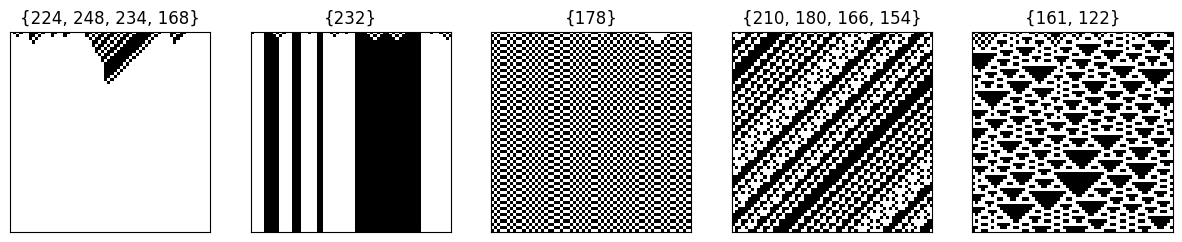

In [6]:
fig, axs = plt.subplots(1,5,figsize=(15,4))
for ax, diag, label in zip(axs, x_train_example, r_train_example):
  ax.imshow(diag, cmap='Greys')
  if OUTPUT_TYPE == 'independent':
    indep_set_lowest = num_to_indep[label[0]]
    indep_set = equiv_ECA_rules[indep_set_lowest] + [int(indep_set_lowest)]
    title = set(indep_set)
  ax.set_title(title)
  ax.set_xticks([])
  ax.set_yticks([])

## Show and define the different augmentations (outside class)

In [7]:
def bool_invert(diagram):
  aug_diagram = 1-diagram
  return aug_diagram

def mirror(diagram): # this is a built-in function of ImageDataGenerator
  aug_diagram = np.flip(diagram, axis=1)
  return aug_diagram

def coarse_grain(diagram, width=2):
  if diagram.shape[0]%2!=0:
    raise Exception("Dimensions for coarse graining must be just right")
  aug_diagram = diagram.reshape(diagram.shape[0]//width,width, diagram.shape[0]//width,width)
  aug_diagram = aug_diagram / width**2 # normalise
  aug_diagram = aug_diagram.mean(axis=(1,3))
  # make sure that the aug image has the same dimensionality
  aug_diagram = np.repeat(np.repeat(aug_diagram, 2, axis=0), 2, axis=1)
  aug_diagram = np.expand_dims(aug_diagram,axis=2)
  return aug_diagram

def salt_and_pepper(diagram, fraction=0.1):
  sp_diagram = np.random.choice([0,1], size=diagram.shape, p=[1-fraction, fraction])
  aug_diagram = np.abs(sp_diagram - diagram)
  return aug_diagram

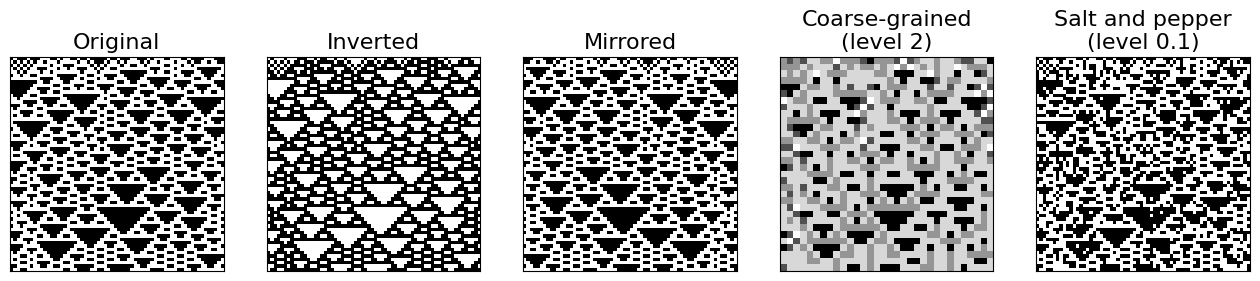

In [8]:
# Generate examples for every augmentation
SAVEFIG=False
SAVENAME="augmentation-examples.pdf"

salt_and_pepper_fraction = 0.1

figsize=16
title_size=16
fig, axs = plt.subplots(1,5, figsize=(figsize, 5*figsize))
aug_names = ["Original","Inverted","Mirrored","Coarse-grained\n(level 2)",f"Salt and pepper\n(level {salt_and_pepper_fraction})"]
original_diagram = x_train_example[4]
aug_diagrams = [original_diagram, bool_invert(original_diagram), mirror(original_diagram),
                coarse_grain(original_diagram), salt_and_pepper(original_diagram, fraction = salt_and_pepper_fraction)]
for i in range(5):
  aug_name = aug_names[i]
  aug_diagram = aug_diagrams[i]
  axs[i].imshow(aug_diagram, cmap='Greys')
  axs[i].set_title(aug_name, size=title_size)
  axs[i].set_xticks([])
  axs[i].set_yticks([])

if SAVEFIG:
  plt.savefig(f'{images_dir}/{SAVENAME}', bbox_inches='tight')

## Show and define the different augmentations (custom class method)

In [9]:
# write a custom class

class CustomDataGenerator(ImageDataGenerator):
    def __init__(self,
                bool_invert: bool = False,
                mirror: bool = False,
                coarse_grain: bool = False,
                salt_and_pepper: bool = False,
                salt_and_pepper_fraction = 0.1,
                **kwargs) -> None:

      # Declare a processing functions
      super().__init__(
          preprocessing_function=self.actions,
          **kwargs)

      # define internal Booleans for the custom augmentations
      self.bool_invert = bool_invert
      self.mirror = mirror # note that this aug already exists, but we bypass it (make our own version)
      self.coarse_grain = coarse_grain
      self.salt_and_pepper = salt_and_pepper
      self.selected_augs_bool = [bool_invert, mirror, coarse_grain, salt_and_pepper]

      self.salt_and_pepper_fraction = 0.01 # hard-coded

    def actions(self, image: np.ndarray) -> np.ndarray:
      all_augs = np.array(['bool_invert',
                      'mirror',
                      'coarse_grain',
                      'salt_and_pepper'])
      selected_augs_str  = ['none']
      for aug_bool, aug_str in zip(self.selected_augs_bool, all_augs):
        if aug_bool:
          selected_augs_str.append(aug_str)
      # randomly pick a SINGLE action. Note that we are not combining actions.
      aug = np.random.choice(selected_augs_str)
      if aug == 'bool_invert':
        return self._bool_invert(image)
      elif aug == 'mirror':
        return self._mirror(image)
      elif aug == 'coarse_grain':
        return self._coarse_grain(image)
      elif aug == 'salt_and_pepper':
        return self._salt_and_pepper(image)
      else:
        return image

    def _bool_invert(self, image: np.ndarray) -> np.ndarray:
      aug_image = 1-image
      return aug_image

    def _mirror(self, image: np.ndarray) -> np.ndarray: # this is a built-in function of ImageDataGenerator
      aug_diagram = np.flip(image, axis=1)
      return aug_diagram

    def _coarse_grain(self, image: np.ndarray) -> np.ndarray:
      # missing: shape is changed
      width=image.shape[0]
      height=image.shape[1]
      if width%2!=0 or height%2!=0:
        raise Exception("Image dimensions must be even for coarse graining to apply properly.")
      aug_image= image.reshape(image.shape[0]//2,2, image.shape[0]//2,2)
      aug_image = aug_image / width**2 # normalise
      aug_image = aug_image.mean(axis=(1,3))
      # make sure that the aug image has the same dimensionality
      aug_image = np.repeat(np.repeat(aug_image, 2, axis=0), 2, axis=1)
      # add the final dimension again
      aug_image = np.expand_dims(aug_image,axis=2)
      return aug_image

    def _salt_and_pepper(self, image: np.ndarray) -> np.ndarray:
      fraction=self.salt_and_pepper_fraction
      sp_image = np.random.choice([0,1], size=image.shape, p=[1-fraction, fraction])
      aug_image = np.abs(sp_image - image)
      return aug_image

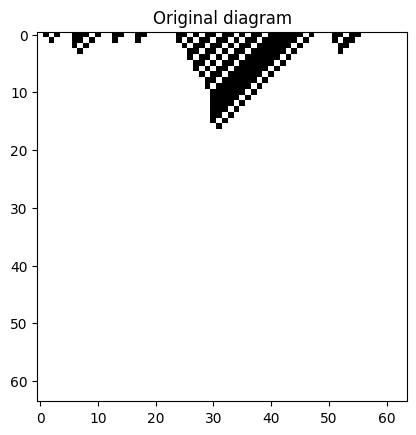

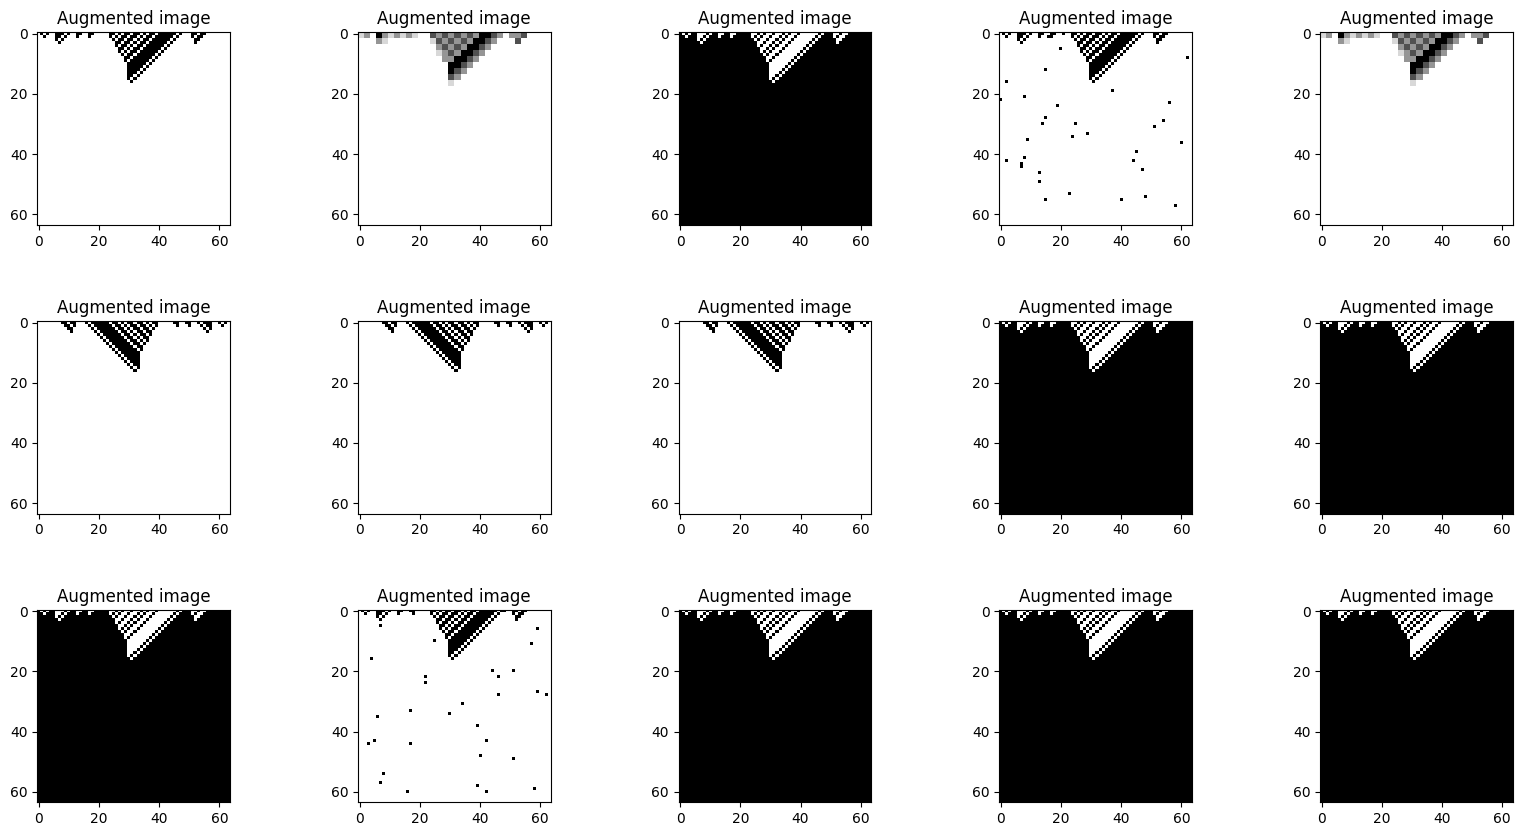

In [10]:
# An object from the class ImageDataGenerator will do 'on-the-fly' data augmentation
# every time you call its function .flow()

# Note that not all options are used here: check the docs for additional info
# the class also contains a 'hook' for adding your own augmentation functions

bool_invert = True
mirror = True
coarse_grain = True
salt_and_pepper = True

datagen = CustomDataGenerator(
        bool_invert=bool_invert,
        mirror=mirror,
        coarse_grain=coarse_grain,
        salt_and_pepper=salt_and_pepper)

# select and show an image from the training set
img_index = 0

plt.figure()
plt.imshow(x_train_example[img_index],  interpolation='None', cmap='Greys')
plt.title("Original diagram")
plt.show()

testit = datagen.flow(x_train_example[img_index:img_index+1], batch_size=1)

# generate 15 augmented images (the first one is the original image)
f = plt.figure(figsize=(20,10))
for idx in range(15):
    plt.subplot(3,5,idx+1)
    plt.subplots_adjust(hspace=0.5)
    plt.title("Augmented image")
    plt.imshow(testit.next()[0,:,:,:],  interpolation='None', cmap='Greys')
plt.show()

# Designing and running the convolutional neural network

In [11]:
def silverman_model_trimmed(diagram_dims=(64, 64, 1), conv_kernel_dims=(3,3), dilation_rate=(1,1), output_type='classes'):
    # output_type param should be 'classes' or 'rules' or 'independent'

    # tell the model which input shape the samples will have
    inputs = Input(diagram_dims, dtype=tf.float32)

    # Conv block, width = 4
    x = Conv2D(4, conv_kernel_dims, padding='valid', dilation_rate=dilation_rate)(inputs)
    x = Activation('relu')(x)

    # Conv block, width = 4
    x = Conv2D(4, conv_kernel_dims, padding='valid', dilation_rate=dilation_rate)(x)
    x = Activation('relu')(x)

    # MaxPool layer 2x2
    x = MaxPooling2D()(x)

    # conv block, width = 4
    x = Conv2D(4, conv_kernel_dims, padding='valid')(x)
    x = Activation('relu')(x)

    # conv block, width = 4
    x = Conv2D(4, conv_kernel_dims, padding='valid')(x)
    x = Activation('relu')(x)

    # global max pooling
    x = GlobalMaxPooling2D()(x)

    # and finally the linear classification output layer
    if output_type=='classes':
      x = Dense(16)(x)
      output = Dense(5, activation="softmax")(x)
    elif output_type=='rules':
      output = Dense(256, activation="softmax")(x)
    elif output_type=='independent':
      output = Dense(88, activation="softmax")(x)
    else:
      raise Exception("Parameter 'output_type' should be either 'classes' (5-fold) or 'rules' (256-fold).")
    model = tf.keras.Model(inputs=inputs, outputs=output)

    # Note that, in contrast to the first graded assignment,
    # we have taken the model compilation out of this function (it is done in the model training block)

    return model

In [13]:
bool_invert = True
mirror = True
coarse_grain = True
salt_and_pepper = True

RUN_AGAIN = False
SAVE_AGAIN = False

model_name = f"reproducing_silverman2019_trimmed_{OUTPUT_TYPE}_2x2-4-4-MP-4-4-16"
if bool_invert:
  model_name += "_bool-invert"
if mirror:
  model_name += "_mirror"
if coarse_grain:
  model_name += "_coarse-grain"
if salt_and_pepper:
  model_name += "_salt-and-pepper0p01"

# model params
diagram_dims = (64,64,1)
conv_kernel_dims = (2, 2)
dilation_rate = (1,1)

if RUN_AGAIN:
  N_train = x_train.shape[0]
  batch_size = 64
  batches_per_epoch = int(N_train/batch_size)
  epochs = 100
  LR = 0.001 # this is quite low
  stopping_patience = 5
  stopping_delta = 0.00001 # this is also very restrictive and will make the training last for a loooong time

  model_augmented = silverman_model_trimmed(diagram_dims=diagram_dims, conv_kernel_dims=conv_kernel_dims, output_type=OUTPUT_TYPE)
  model_augmented.summary()

  model_augmented.compile(loss='categorical_crossentropy',
                  optimizer=Adam(learning_rate=LR),
                  metrics=['accuracy'])

  stopping_callback = tf.keras.callbacks.EarlyStopping(monitor='val_accuracy',
                                                      patience=stopping_patience,
                                                      min_delta=stopping_delta,
                                                      verbose = 1,
                                                      restore_best_weights=True)

  datagen = CustomDataGenerator(
        bool_invert=bool_invert,
        mirror=mirror,
        coarse_grain=coarse_grain,
        salt_and_pepper=salt_and_pepper)

  # Compute quantities required for some augmentation functions
  # (e.g., std, mean, and principal components if ZCA whitening is applied).
  datagen.fit(x_train, augment=True)

  history_augmented = model_augmented.fit(datagen.flow(x_train, r_train, batch_size=batch_size),
                          epochs=epochs,
                          verbose=1,
                          validation_data=(x_val, r_val),
                          shuffle=True,
                          callbacks = [stopping_callback])

  if SAVE_AGAIN:
    model_augmented.save(f"{models_dir}/{model_name}")

else:
  model_augmented = load_model(f"{models_dir}/{model_name}")

OSError: No file or directory found at /content/gdrive/My Drive/Colab Notebooks/Cellular Automata/Spacetime Diagram Classification/Models/reproducing_silverman2019_trimmed_classes_2x2-4-4-MP-4-4-16_bool-invert_mirror_coarse-grain_salt-and-pepper0p01

2048/2048 [==============================] - 5s 2ms/step - loss: 1.2758 - accuracy: 0.5617
Training set Accuracy:0.561600
Training set Loss:1.276794

Validation set Accuracy:0.561661
Validation set Loss:1.275757



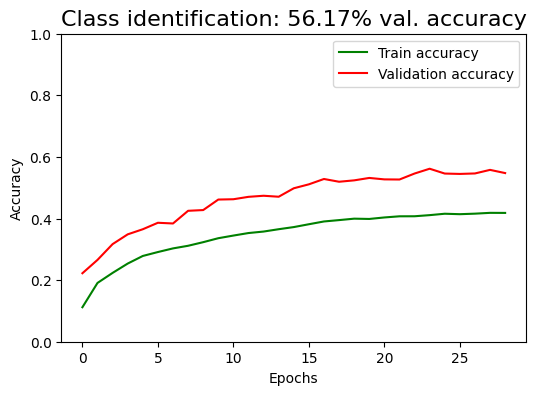

In [14]:
CALCULATE_AGAIN = True
SAVE_FIG = True

if CALCULATE_AGAIN:
  [train_loss, train_accuracy] = model_augmented.evaluate(x_train, r_train, verbose=1)
  [val_loss, val_accuracy] = model_augmented.evaluate(x_val, r_val, verbose=1)

print("Training set Accuracy:{:7.6f}".format(train_accuracy))
print("Training set Loss:{:7.6f}\n".format(train_loss))

print("Validation set Accuracy:{:7.6f}".format(val_accuracy))
print("Validation set Loss:{:7.6f}\n".format(val_loss))

#Now we visualise what happened during training
plot_history(history_augmented, y_axis_bounds=[0,1], show_loss=False)
plt.title(f'Class identification: {round(100*val_accuracy,2)}% val. accuracy', size=16)

if SAVE_FIG:
  plt.savefig(f'{images_dir}/accuracy-hist_{model_name}.pdf', bbox_inches='tight')

# Analysis of the model performance

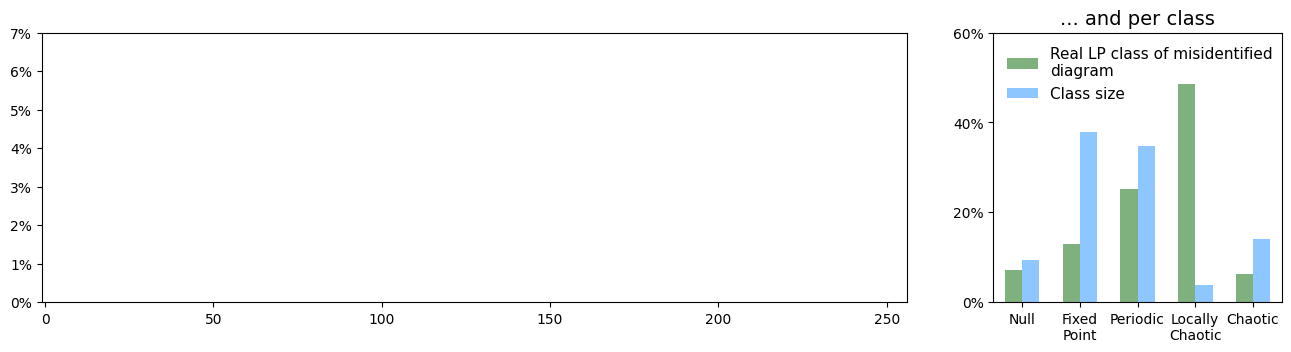

In [ ]:
CALCULATE_AGAIN = False
SAVEFIG=False
SAVENAME='trimmed-augmented-model_misidentified-val-set.pdf'

if CALCULATE_AGAIN:
  # the predictions are class probabilities,
  # the argmax code line below finds the index of the class with the highest probability
  # predictions_rules = model_default_rules.predict(x_val)
  predictions_classes = model_augmented.predict(x_val)

  # val_predicted_rule = np.argmax(predictions_rules,axis=1)
  val_predicted_class = np.argmax(predictions_classes, axis=1)

ugent_blue = (30/255,100/255,200/255)
ugent_yellow = (255/255, 210/255, 0/255)

color1 = 'maroon'
color2 = 'darkgreen'

# misclassified_rules_idxs, = np.where(val_predicted_rule!=r_val_rule[:,0]) # too much RAM!
# misclassified_rules_real = r_val_rule[misclassified_rules_idxs,0]
# misclassified_rules_guess = val_predicted_rule[misclassified_rules_idxs]

misclassified_classes_idxs, = np.where(val_predicted_class!=r_val_class[:,0]) # too much RAM!
misclassified_classes_real = r_val_class[misclassified_classes_idxs,0]
misclassified_classes_guess = val_predicted_class[misclassified_classes_idxs]

# misclassified_rules_sizes_real = np.array([np.count_nonzero(misclassified_rules_real==i) for i in range(256)])
# misclassified_rules_sizes_guess = np.array([np.count_nonzero(misclassified_rules_guess==i) for i in range(256)])

misclassified_classes_sizes_real = np.array([np.count_nonzero(misclassified_classes_real==i) for i in range(5)])
misclassified_classes_sizes_guess = np.array([np.count_nonzero(misclassified_classes_guess==i) for i in range(5)])

fig, axs = plt.subplots(1,2,figsize=(16,3.5), width_ratios=(3,1))
plt.subplots_adjust(wspace=0.15)
labelsize=12

# axs[0].bar(np.arange(256), misclassified_rules_sizes_real / sum(misclassified_rules_sizes_real), width=1,
#        color=color2, alpha=.5,
#        label='Real rule of misidentified diagram')

width=0.3
bar_offset=width/2
axs[1].bar(np.arange(5)-bar_offset, misclassified_classes_sizes_real / sum(misclassified_classes_sizes_real), width=width,
       color=color2, alpha=.5,
       label='Real LP class of misidentified\ndiagram')

# add prevalence of every LP class
prevalence_color='dodgerblue'
class_prevalences = []
for key, item in Li_Packard_dict.items():
  class_prevalence = len(item) / 256
  class_prevalences.append(class_prevalence)
axs[1].bar(np.arange(5)+bar_offset, class_prevalences, width=width, color=prevalence_color, alpha=0.5, label='Class size')

axs[0].set_xlim([-1,256])
axs[0].set_ylim([0, 0.07])
axs[0].set_yticks([0, 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07])
axs[0].set_yticklabels(['0%', '1%', '2%', '3%', '4%', '5%', '6%', '7%'])
# axs[0].set_xticklabels(num_to_class.keys(), size=labelsize)

axs[1].set_ylim([0, .6])
axs[1].set_yticks([0, 0.2, 0.4, 0.6])
axs[1].set_yticklabels(['0%', '20%', '40%', '60%'])

axs[1].set_xlim([-.5,4.5])
axs[1].set_xticks([0, 1, 2, 3, 4])
xticklabels=['Null','Fixed\nPoint', 'Periodic','Locally\nChaotic','Chaotic']
axs[1].set_xticklabels(xticklabels)
# axs[1].set_ylim([0, 0.07])
# axs[1].set_yticks([0, 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07])
# axs[1].set_yticklabels(['0%', '1%', '2%', '3%', '4%', '5%', '6%', '7%'])
# axs[1].set_xticklabels(num_to_class.keys(), size=labelsize)

axs[1].legend(prop={'size':labelsize-1}, ncols=1, loc='upper left', frameon=False)
# axs[0].set_title(f"All {len(misclassified_rules_idxs)} misidentified diagrams from validation set (size {r_val_rule.shape[0]}), per rule", fontsize=labelsize+2)
axs[1].set_title(f"... and per class", fontsize=labelsize+2)

if SAVEFIG:
  plt.savefig(f'{images_dir}/{SAVENAME}', bbox_inches='tight')

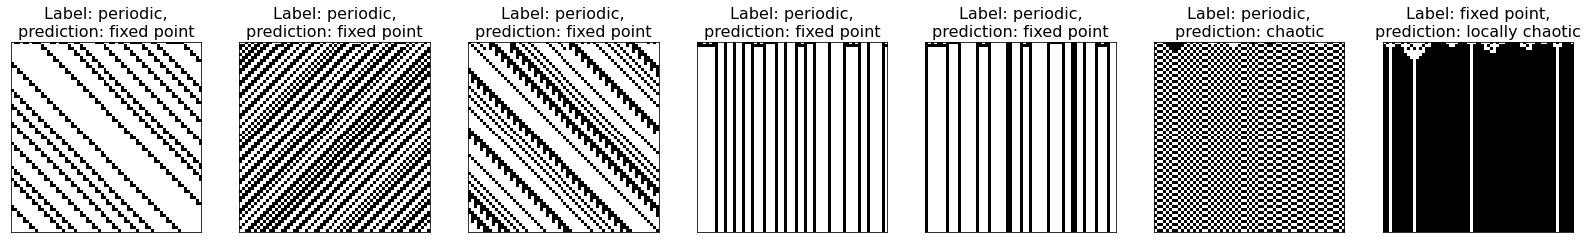

In [ ]:
# Show which diagram has been classified wrongly

fix, axs = plt.subplots(1, len(misclassified), figsize=(28, 4))

for i in range(len(misclassified)):
  mis_index = misclassified[i]
  actual_class = num_to_class[int(r_test_class_all[mis_index,0])]
  predicted_class = num_to_class[int(test_predicted_class[mis_index])]
  axs[i].set_title("Label: " + actual_class
          + ",\nprediction: " + predicted_class, size=16)
  axs[i].imshow(x_test[mis_index,:,:,0], cmap='Greys', interpolation='None')
  axs[i].set_xticks([])
  axs[i].set_yticks([])

# Complete run on all training data

In [14]:
bool_invert = True
mirror = True
coarse_grain = True
salt_and_pepper = False

RUN_AGAIN = False
SAVE_AGAIN = False

model_name = f"reproducing_silverman2019_trimmed_{OUTPUT_TYPE}_final_2x2-4-4-MP-4-4-16"
if bool_invert:
  model_name += "_bool-invert"
if mirror:
  model_name += "_mirror"
if coarse_grain:
  model_name += "_coarse-grain"
if salt_and_pepper:
  model_name += "_salt-and-pepper0p01"

# model params
diagram_dims = (64,64,1)
conv_kernel_dims = (2, 2)
dilation_rate = (1,1)

if RUN_AGAIN:
  N_train = x_train_all.shape[0]
  batch_size = 64
  batches_per_epoch = int(N_train/batch_size)
  epochs = 100
  LR = 0.0005 # this is quite low
  stopping_patience = 5
  stopping_delta = 0.00001 # this is also very restrictive and will make the training last for a loooong time

  model_augmented = silverman_model_trimmed(diagram_dims=diagram_dims, conv_kernel_dims=conv_kernel_dims, output_type=OUTPUT_TYPE)
  model_augmented.summary()

  model_augmented.compile(loss='categorical_crossentropy',
                  optimizer=Adam(learning_rate=LR),
                  metrics=['accuracy'])

  datagen = CustomDataGenerator(
        bool_invert=bool_invert,
        mirror=mirror,
        coarse_grain=coarse_grain,
        salt_and_pepper=salt_and_pepper)

  # Compute quantities required for some augmentation functions
  # (e.g., std, mean, and principal components if ZCA whitening is applied).
  datagen.fit(x_train_all, augment=True)

  history_augmented = model_augmented.fit(datagen.flow(x_train_all, r_train_all, batch_size=batch_size),
                          epochs=epochs,
                          verbose=1,
                          shuffle=True)

  if SAVE_AGAIN:
    model_augmented.save(f"{models_dir}/{model_name}")

else:
  model_augmented = load_model(f"{models_dir}/{model_name}")

In [15]:
CALCULATE_AGAIN = True
SHOW_FIG = False
SAVE_FIG = False

if CALCULATE_AGAIN:
  [train_loss, train_accuracy] = model_augmented.evaluate(x_train_all, r_train_all, verbose=1)
  [test_loss, test_accuracy] = model_augmented.evaluate(x_test, r_test, verbose=1)

print("Training set Accuracy:{:7.6f}".format(train_accuracy))
print("Training set Loss:{:7.6f}\n".format(train_loss))

print("Test set Accuracy:{:7.6f}".format(test_accuracy))
print("Test set Loss:{:7.6f}\n".format(test_loss))

if SHOW_FIG:
  #Now we visualise what happened during training
  plot_history(history_augmented, y_axis_bounds=[0,1], show_loss=False, show_val=False)
  plt.title(f'{OUTPUT_TYPE} identification: {round(100*test_accuracy,2)}% test accuracy', size=16)

  if SAVE_FIG:
    plt.savefig(f'{images_dir}/accuracy-hist_{model_name}.pdf', bbox_inches='tight')

else:
  print("No figure to show")
  if SAVE_FIG:
    print(f"No figure to save")

1024/1024 [==============================] - 21s 21ms/step - loss: 0.0805 - accuracy: 0.9817
Training set Accuracy:0.981232
Training set Loss:0.082887

Test set Accuracy:0.981689
Test set Loss:0.080475

No figure to show


In [20]:
r_test.shape

(32768, 5)

1024/1024 [==============================] - 21s 20ms/step


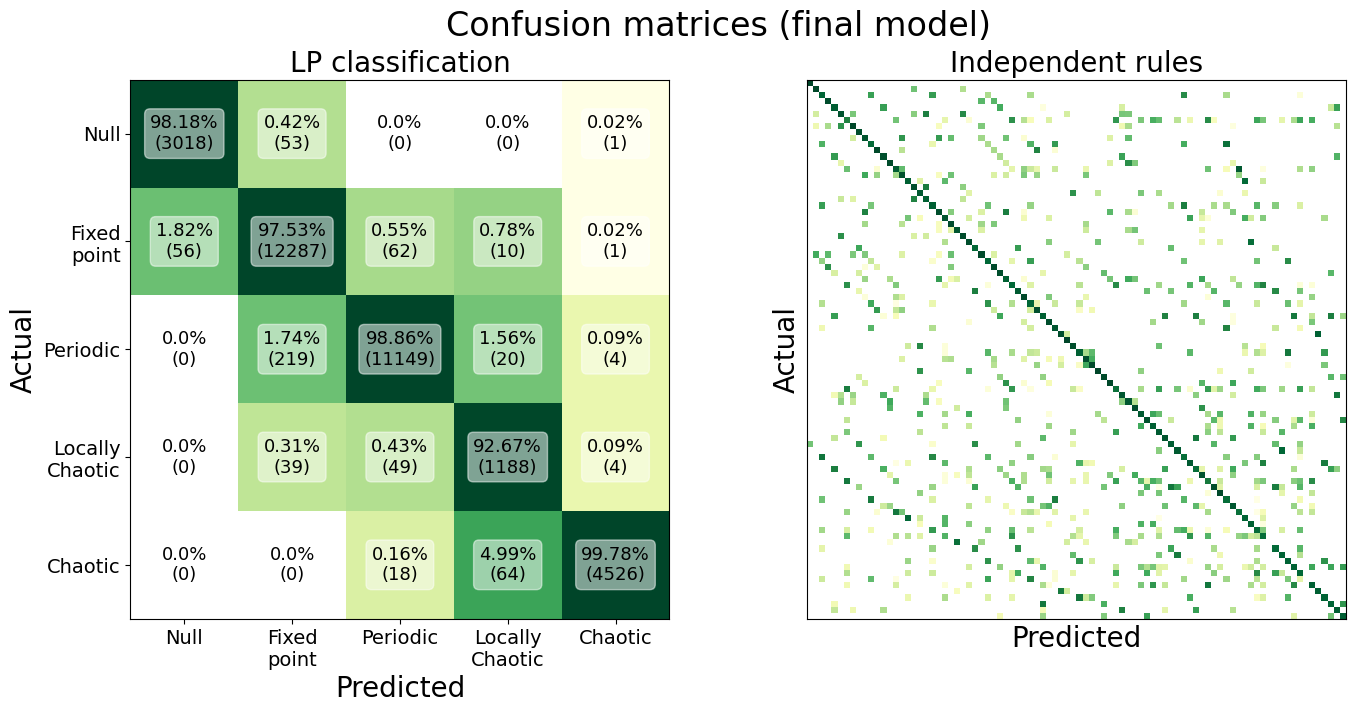

In [4]:
from sklearn.metrics import confusion_matrix
CALCULATE_AGAIN = True

SAVEFIG=False
SAVENAME='trimmed-augmented-model_confusion-matrix_test-set.pdf'

# Load the data and the labels
test_name_prefix = "ECAs_128sims-per-rule_64x64"
test_diagram_name = test_name_prefix + "_test_diagrams.npy"
test_label_name5  = test_name_prefix + "_test_labels_class.npy"
test_label_name88 = test_name_prefix + "_test_labels_indep.npy"
x_test = np.load(f"{files_dir}/{test_diagram_name}")
r_test5 = np.load(f"{files_dir}/{test_label_name5}")
r_test88 = np.load(f"{files_dir}/{test_label_name88}")

# load models
model_name5 = f"reproducing_silverman2019_trimmed_classes_final_2x2-4-4-MP-4-4-16_bool-invert_mirror_coarse-grain"
model_name88 = f"reproducing_silverman2019_trimmed_independent_final_2x2-4-4-MP-4-4-16_bool-invert_mirror_coarse-grain"
model_augmented5  = load_model(f"{models_dir}/{model_name5}")
model_augmented88 = load_model(f"{models_dir}/{model_name88}")

if CALCULATE_AGAIN:
  # calculate predictions
  predictions5  = model_augmented5.predict(x_test)
  predictions88 = model_augmented88.predict(x_test)

  # put predictions in correct shape
  predictions88 = np.argmax(predictions88, axis=1)
  predictions5  = np.argmax(predictions5, axis=1)

# create confusion matrix np.array (classes)
cm_norm5 = confusion_matrix(r_test5, predictions5, normalize='pred')
cm_abs5 = confusion_matrix(r_test5, predictions5)

# create confusion matrix np.array (independent rules)
cm_norm88 = confusion_matrix(r_test88, predictions88, normalize='pred')
cm_abs88 = confusion_matrix(r_test88, predictions88)

# put in desired shape
cm_norm5 = np.round(100*cm_norm5, 2)
cm_abs5 = cm_abs5.astype(int)
cm_norm88 = np.round(100*cm_norm88, 2)
cm_abs88 = cm_abs88.astype(int)

# draw confusion matrix
fig, axs = plt.subplots(1,2,figsize=(16,7))
axs[0].imshow(cm_norm5, cmap='YlGn', norm='log')
axs[1].imshow(cm_norm88, cmap='YlGn', norm='log')

# create axis ticks
ticks = np.arange(5)
axs[0].set_xticks(ticks)
axs[0].set_yticks(ticks)
ticks = np.arange(88)
axs[1].set_xticks(ticks)
axs[1].set_yticks(ticks)

# ... and labels
ticklabels = ["Null", "Fixed\npoint", "Periodic", "Locally\nChaotic", "Chaotic"]
axs[0].set_xticklabels(ticklabels, fontsize=14)
axs[0].set_yticklabels(ticklabels, fontsize=14)

axs[1].set_xticks([])
axs[1].set_yticks([])

# convert to str for labels (LP classes)
cm_norm5 = cm_norm5.astype(str)
cm_abs5  = cm_abs5.astype(str)

# create percentage sign (LP classes)
right_perc = np.full(cm_norm5.shape, '%', dtype=object)
cm_norm5 = np.add(cm_norm5, right_perc)

# create absolute value in parentheses (LP classes)
left_par = np.full(cm_abs5.shape, '(', dtype=object)
right_par = np.full(cm_abs5.shape, ')', dtype=object)
cm_abs = np.add(left_par, cm_abs5)
cm_abs = np.add(cm_abs, right_par)

# add percentage and abs together
newlines = np.full(cm_norm5.shape, '\n', dtype=object)
cm_norm5 = np.add(cm_norm5, newlines)
cm_labels5 = np.add(cm_norm5, cm_abs)

# add labels in fancy boxes
for (j,i), label in np.ndenumerate(cm_labels5):
    txt = axs[0].text(i,j,label,ha='center', va='center', size=13)
    txt.set_bbox(dict(facecolor='white', alpha=0.5, edgecolor='white', boxstyle='round'))

# add title and axis names
axs[0].set_title('LP classification', fontsize=20)
axs[1].set_title('Independent rules', fontsize=20)

axs[0].set_xlabel('Predicted', fontsize=20)
axs[1].set_xlabel('Predicted', fontsize=20)
axs[0].set_ylabel('Actual', fontsize=20)
axs[1].set_ylabel('Actual', fontsize=20)

fig.suptitle('Confusion matrices (final model)', size=24)

if SAVEFIG:
  plt.savefig(f'{images_dir}/{SAVENAME}', bbox_inches='tight')

In [ ]:
# find examples of wrong predictions
wrong_predictions = np.where(predictions5 != r_test5)

wrong_predictions.shape